<a href="https://colab.research.google.com/github/jokuhrman/math289/blob/main/llm_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LLM Architecture (I)

## MATH 289, Fall 2026 by Shurui Liu 10/12/2026


How to use this notebook: run the *Setup* cell once (it downloads GPT-2, about 550 MB, the first time). All other code
cells are one- to five-line demos. You do not need to read the setup code.

Recouses used in this notebook:
1. Pictures marked CS224N are from Stanford's course *Natural Language Processing with Deep Learning* (Winter 2026 slides, [web.stanford.edu/class/cs224n](https://web.stanford.edu/class/cs224n/)). Numbers from training runs are from CS336
2. (*Language Modeling from Scratch*), assignment 1, as solved in
[github.com/srliu3264/cs336_hw1](https://github.com/srliu3264/cs336_hw1).

**Plan of the week** (this notebook: Lecture 1; the other lecture is in `llm_lecture2.ipynb`)

| Lecture 1 (Mon) | | Lecture 2 (Wed) | |
|---|---|---|---|
| 0–10 | the life cycle of an LLM | 0–10 | the life cycle, revisited |
| 10–20 | attention and heads, reviewed | 10–30 | the training loss: entropy, cross-entropy, KL |
| 20–30 | what is a token; tokenizer training | 30–50 | design choices in open-source models |
| 30–50 | embeddings: tokens become vectors | 50–70 | the life cycle of a token in training |
| 50–60 | the output layer | 70–80 | wrap-up |
| 60–80 | inference: frozen weights, sampling, temperature | | |

## Setup (run once)

Everything below runs on a CPU. On Google Colab all packages are preinstalled; on a laptop, `pip install torch transformers matplotlib tiktoken` once.

In [ ]:
# Run this cell once. It loads GPT-2 and defines the small helper functions used by the demos. No need to read it.
import importlib, subprocess, sys
for pkg in ["torch", "transformers", "matplotlib", "tiktoken"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import math, json, html, warnings
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display
import transformers, huggingface_hub
from transformers import AutoTokenizer, GPT2LMHeadModel
warnings.filterwarnings("ignore")                                   # keep the library chatter out of the lecture
huggingface_hub.utils.logging.set_verbosity_error(); transformers.utils.logging.set_verbosity_error(); transformers.utils.logging.disable_progress_bar()
torch.manual_seed(289)

MODEL_NAME = "gpt2"                      # 124M parameters. Alternatives: "gpt2-medium" (355M), "gpt2-large" (774M), "gpt2-xl" (1.5B, needs a GPU)
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = GPT2LMHeadModel.from_pretrained(MODEL_NAME, attn_implementation="eager").eval()
E = model.transformer.wte.weight.detach()          # the token embedding matrix, V x d
P = model.transformer.wpe.weight.detach()          # the position embedding matrix, 1024 x d
V, d = E.shape; L, h = model.config.n_layer, model.config.n_head
print(f"loaded {MODEL_NAME}: vocabulary V = {V:,} tokens, vector dimension d = {d}, L = {L} blocks, h = {h} heads per block, "
      f"{sum(p.numel() for p in model.parameters()) / 1e6:.0f} million parameters")

# ---- tokens -------------------------------------------------------------------------------------------
def ids_of(text):      return tokenizer.encode(text)                                   # text -> list of token ids
def tokens_of(text):   return [tokenizer.decode([i]) for i in tokenizer.encode(text)]  # text -> list of token strings

_COLORS = ["#fde68a", "#bfdbfe", "#bbf7d0", "#fecaca", "#ddd6fe", "#fed7aa"]
def show_tokens(text, tok=None, label=None):
    """display `text` cut into tokens; each token gets its own colour. `tok` may be any tokenizer with encode/decode."""
    tok = tok or tokenizer
    pieces = [tok.decode([i]) for i in tok.encode(text)]
    spans = "".join(f'<span style="background:{_COLORS[i % 6]};padding:2px 1px;border-radius:3px;white-space:pre">{html.escape(p)}</span>'
                    for i, p in enumerate(pieces))
    head = f'<span style="color:#64748b;display:inline-block;width:70px">{label}</span>' if label else ""
    display(HTML(f'<div style="font-family:monospace;font-size:15px;line-height:2.0">{head}{spans}'
                 f'<span style="color:#64748b;margin-left:14px">{len(pieces)} tokens / {len(text)} characters</span></div>'))

def train_bpe_demo(text, num_merges):
    """byte-pair encoding on characters, printing each merge (end of a word is marked by '_', as in the slides)"""
    words = {}
    for w in text.split():
        key = tuple(w) + ("_",); words[key] = words.get(key, 0) + 1
    for step in range(1, num_merges + 1):
        pairs = {}
        for w, c in words.items():
            for a, b in zip(w, w[1:]): pairs[(a, b)] = pairs.get((a, b), 0) + c
        if not pairs: break
        (a, b), c = max(pairs.items(), key=lambda kv: kv[1])
        def merged(w):
            out, i = [], 0
            while i < len(w):
                if i < len(w) - 1 and (w[i], w[i + 1]) == (a, b): out.append(a + b); i += 2
                else: out.append(w[i]); i += 1
            return tuple(out)
        words = {merged(w): c for w, c in words.items()}
        print(f"merge {step:2d}: '{a}' + '{b}' -> '{a + b}'   (the pair occurred {c} times)")
    return words

# ---- embeddings ----------------------------------------------------------------------------------------
_En = E / E.norm(dim=1, keepdim=True)              # rows of E scaled to unit length, for cosine similarities
def vec(word):
    """the embedding vector of a word that is a single token (use a leading space: ' theorem')"""
    ids = ids_of(word); assert len(ids) == 1, f"{word!r} is {len(ids)} tokens, not one"; return E[ids[0]]
def cosine(u, v): return float(F.cosine_similarity(u, v, dim=0))
def similarity_heatmap(words):
    S = torch.stack([_En[ids_of(w)[0]] for w in words]); S = S @ S.T
    fig, ax = plt.subplots(figsize=(0.55 * len(words) + 1.5, 0.5 * len(words) + 1))
    ax.imshow(S, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(words))); ax.set_xticklabels(words, rotation=90); ax.set_yticks(range(len(words))); ax.set_yticklabels(words)
    for i in range(len(words)):
        for j in range(len(words)): ax.text(j, i, f"{S[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title("cosine similarity between token embeddings"); plt.tight_layout(); plt.show()
def nearest(word, k=8):
    sims = _En @ _En[ids_of(word)[0]]; sims[ids_of(word)[0]] = -2
    return [tokenizer.decode([i]) for i in sims.topk(k).indices.tolist()]
def analogy(a, b, c, k=4):
    """nearest tokens to  vec(a) - vec(b) + vec(c)  (a, b, c themselves excluded)"""
    ids = [ids_of(w)[0] for w in (a, b, c)]
    sims = _En @ (_En[ids[0]] - _En[ids[1]] + _En[ids[2]])
    for i in ids: sims[i] = -2
    return [tokenizer.decode([i]) for i in sims.topk(k).indices.tolist()]
def pca_plot(words, title=""):
    X = torch.stack([vec(w) for w in words]); X = X - X.mean(0)
    _, _, Vt = torch.linalg.svd(X, full_matrices=False); proj = X @ Vt[:2].T
    fig, ax = plt.subplots(figsize=(6.5, 4.5)); ax.plot(proj[:, 0], proj[:, 1], "-", color="#cbd5e1")
    ax.scatter(proj[:, 0], proj[:, 1], c=range(len(words)), cmap="viridis")
    for w, (x, y) in zip(words, proj): ax.annotate(w.strip(), (x, y), fontsize=9, xytext=(3, 3), textcoords="offset points")
    ax.set_title(title or "embeddings projected on their two principal directions"); plt.tight_layout(); plt.show()
def position_similarity_plot():
    Pn = P / P.norm(dim=1, keepdim=True); C = Pn @ Pn.T
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    axes[0].imshow(C, cmap="RdBu_r", vmin=-1, vmax=1); axes[0].set_title("cosine similarity of position vectors P_t, P_s"); axes[0].set_xlabel("s"); axes[0].set_ylabel("t")
    axes[1].plot(range(1, 400), [C.diagonal(k).mean().item() for k in range(1, 400)]); axes[1].set_xlabel("distance k = t − s"); axes[1].set_ylabel("mean cosine")
    axes[1].set_title("positions close to each other get similar vectors"); plt.tight_layout(); plt.show()
@torch.no_grad()
def vectors_through_the_blocks(text, token):
    """the vector of `token` after 0, 1, ..., L-1 blocks of the model (the residual stream)"""
    states = model(torch.tensor([ids_of(text)]), output_hidden_states=True).hidden_states
    t = tokens_of(text).index(token)
    return [s[0, t] for s in states[:-1]]

# ---- attention -----------------------------------------------------------------------------------------
@torch.no_grad()
def attention_heatmap(sentence, layer, head, ax=None):
    """the attention matrix A of one head on one sentence: row t says where position t looks"""
    A = model(torch.tensor([ids_of(sentence)]), output_attentions=True).attentions[layer][0, head]
    toks = tokens_of(sentence)
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(4.2, 4))
    ax.imshow(A, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(toks))); ax.set_xticklabels(toks, rotation=90, fontsize=8); ax.set_yticks(range(len(toks))); ax.set_yticklabels(toks, fontsize=8)
    ax.set_title(f"block {layer}, head {head}", fontsize=10); ax.set_xlabel("looks at position s"); ax.set_ylabel("position t")
    if own: plt.tight_layout(); plt.show()

# ---- the output layer and sampling -----------------------------------------------------------------------
@torch.no_grad()
def last_vector(ids):
    """the final d-dimensional vector at the last position (after the final normalization)"""
    return model(torch.tensor([ids]), output_hidden_states=True).hidden_states[-1][0, -1]
@torch.no_grad()
def next_token_probs(ids, temperature=1.0):
    """the model's probability distribution for the token that follows `ids`"""
    logits = model(torch.tensor([ids])).logits[0, -1]
    return torch.softmax(logits / temperature, dim=0)
def plot_top_tokens(probs, k=10, title="", ax=None):
    top = probs.topk(k); own = ax is None
    if own: fig, ax = plt.subplots(figsize=(7, 2.8))
    ax.bar(range(k), top.values, color="#3b82f6"); ax.set_xticks(range(k)); ax.set_xticklabels([repr(tokenizer.decode([i])) for i in top.indices], rotation=45, ha="right")
    ax.set_ylabel("probability"); ax.set_title(title, fontsize=10)
    if own: plt.tight_layout(); plt.show()
def generate(prompt, temperature=1.0, max_new_tokens=40, seed=289):
    """append one sampled token at a time (temperature 0 = always the most likely token); prints as it goes"""
    torch.manual_seed(seed); ids = ids_of(prompt); print(prompt, end="")
    for _ in range(max_new_tokens):
        probs = next_token_probs(ids[-1024:], temperature) if temperature > 0 else None
        nxt = int(torch.multinomial(probs, 1)) if temperature > 0 else int(next_token_probs(ids[-1024:]).argmax())
        ids.append(nxt); print(tokenizer.decode([nxt]), end="", flush=True)
    print()
print("helpers ready")

loaded gpt2: vocabulary V = 50,257 tokens, vector dimension d = 768, L = 12 blocks, h = 12 heads per block, 124 million parameters
helpers ready


## 1. The life cycle of an LLM &nbsp;&nbsp; <small>(0–10 min)</small>

**What a language model is.** Fix a finite ordered set $\mathcal{V}$ of *tokens* (To be defined later).


A **large language model** is a next token predictor $p_\theta$, namely it takes the tokens seen so far and
returns a probability for each possible next token,

$$ p_\theta(x_{t} = v \mid x_1, \dots, x_{t-1}) \;=\; \big[f_\theta(x_1,\dots,x_{t-1})\big]_{v\in\mathcal{V}}. $$

* $\theta$ is a list of real numbers, the **parameters** (also called *weights*): They are the numbers stored in a "checkpoint" file; adjusted/learnt during the training process.
* The **architecture** is the *form* of $f_\theta$: which matrices multiply which vectors in which order.
  It is the subject of this week.
* **Training** means finding $\theta$ so that $p_\theta$ assigns high probability to real text (i.e. minimizing the training loss function).
* **Inference** means evaluating $p_\theta$ for a fixed $\theta$ to predict the next token.


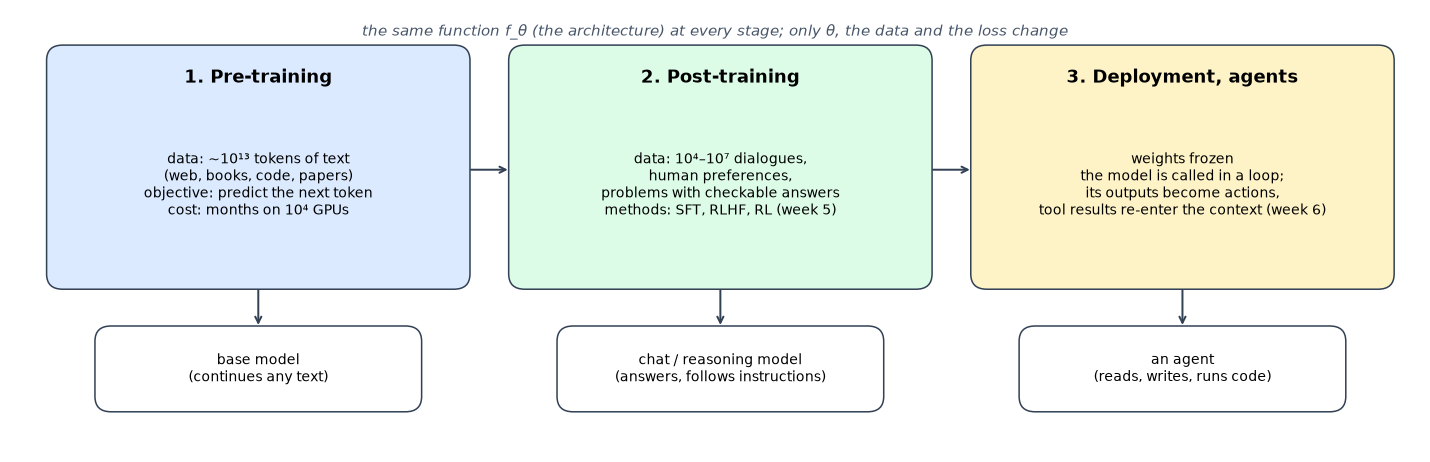

*The three stages of an LLM. Only pre-training and (part of) post-training change the parameters; an agent runs the frozen model in a loop.*

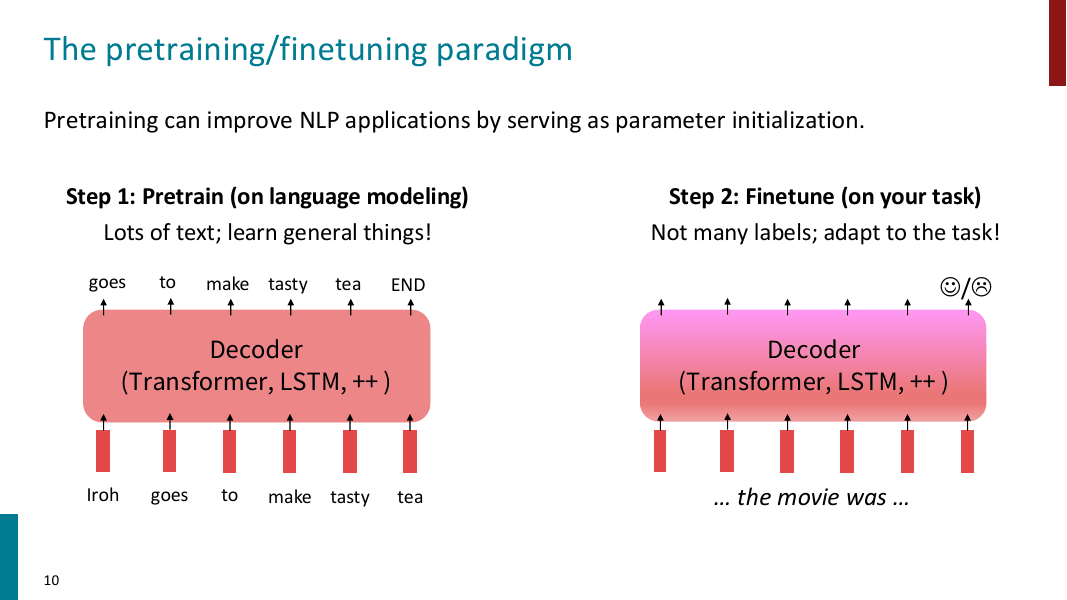

*Stage 1 and the start of stage 2: pre-train on plain text, then fine-tune on a task. — slide 10 of Stanford CS224N Lecture 8 (post-training), Winter 2026.*

**Orders of magnitude** (published numbers).

- GPT-2 XL (2019): 1.5 billion parameters, trained on 40 GB of web text.
- Llama 3 405B (2024): $15.6\times 10^{12}$ tokens, about $4\times10^{25}$ floating-point operations.
- DeepSeek-V3 (2024): 671 billion parameters, of which 37 billion are used for any given token, $14.8\times10^{12}$ tokens.

Pre-training a frontier model costs tens of millions of dollars; evaluating it on one token costs roughly $2\times$(active parameters) operations, a fraction of a cent.

Notations reviewed

| symbol | meaning | GPT-2 small |
|---|---|---|
| $V$ | number of tokens in the vocabulary | 50,257 |
| $d$ | dimension of the vector attached to each token | 768 |
| $T$ | length of the input, in tokens (the *context*) | up to 1,024 |
| $L$ | number of identical blocks stacked on top of each other | 12 |
| $h$ | number of attention heads in each block | 12 |

## 2. Attention and heads, reviewed &nbsp;&nbsp; <small>(10–20 min)</small>

Last week ended with attention.

### 2.1 Settings and Mathematical form
The input is a sequence of $T$ vectors $x_1, \dots, x_T \in \mathbb{R}^d$, one per token.

In matrix form, with $X \in \mathbb{R}^{T\times d}$ holding the input vectors as rows, the whole operation is two matrix
products and a row-wise softmax,

$$ \mathrm{Attention}(X) \;=\; \operatorname{softmax}\!\Big(\frac{(XQ^{\top})(XK^{\top})^{\top}}{\sqrt{d_k}}\Big)\, XV^{\top}, $$

where the division by $\sqrt{d_k}$ ($d_k=d/h$ = dimension of the queries) only keeps the scores from growing with the
dimension. The $T\times T$ matrix of weights $\alpha_{ij}$ is the **attention pattern**: row $i$ is a probability
distribution over positions, "where position $i$ looks".

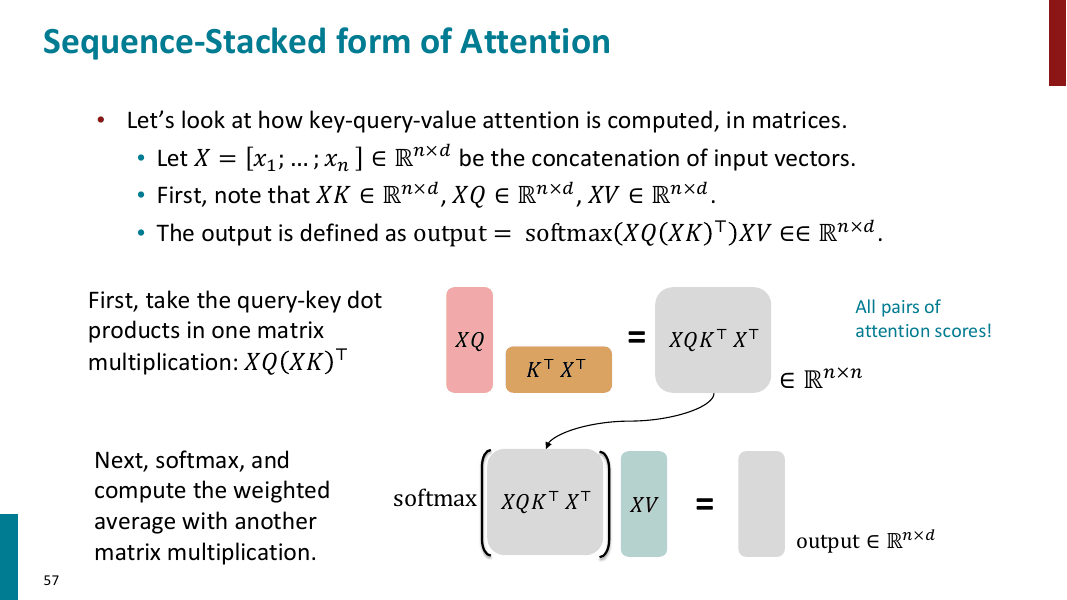

*The same computation written with matrices: all scores at once, then a softmax row by row, then one more product. — slide 56 of Stanford CS224N Lecture 5 (transformers), Winter 2026.*

### 2.2 Multi Heads

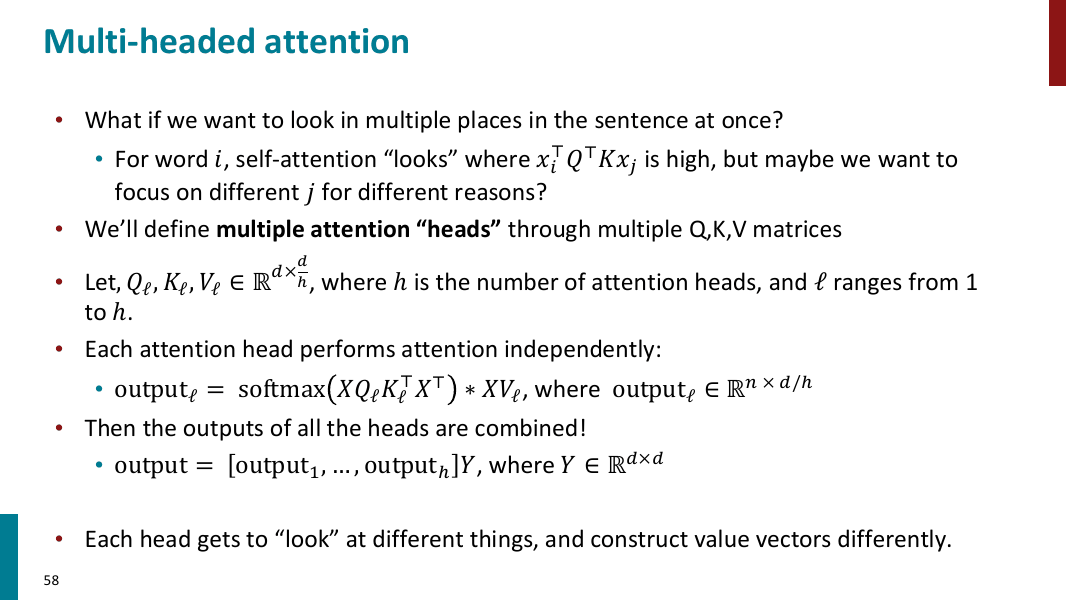

*Multi-head attention: h attentions in parallel, in dimension d/h each, concatenated at the end. — slide 57 of Stanford CS224N Lecture 5 (transformers), Winter 2026.*

**Heads.** One lookup per position is restrictive: a word may need to look at its subject for one reason and at a
nearby adjective for another. So each block runs $h$ attentions **in parallel** with their own matrices
$Q_\ell, K_\ell, V_\ell$ ($\ell = 1, \dots, h$), each producing vectors of dimension $d/h$, and concatenates the $h$
outputs back into one vector of dimension $d$ (followed by one more matrix, $W_O$). Each of these is a **head**.
Different heads learn to look at different things.

**Concrete numbers.** GPT-2 small: $d = 768$, $h = 12$ heads, so each head works in dimension $d_k = 64$; the matrices
$Q, K, V, W_O$ of a block hold $4 d^2 \approx 2.4$ million parameters. GPT-2 XL: $d = 1600$, $h = 25$, again $d_k = 64$.



**Computing all scores $e_{ij}$ costs $T^2 d$ multiplications per block**: this is the **quadratic cost of long contexts**.

### 2.3 Several ways of understanding "attention"

My personal understandings of "attention", which evolved as I learnt more:

**Understanding 1: Attention is to learn 3 representations of a token vector**, query & key & value, aka how it relates to other tokens and how much it matters.

**Understanding 2:** Attention is the operation that lets the vector at one position **collect information from the other
positions** in the context window. This fixes the vanishing gradient issue in recurrent methods.

**Understanding 3: Attention is a weighted average, and a weighted average is a soft lookup.** Think of a dictionary with keys and
values. A hard lookup finds the one key equal to the query and returns its value. Attention compares the query with
*every* key, turns the comparisons into weights that sum to one, and returns the weighted average of all values.

**Understanding 4:** It works super well in practice and in many scenarios, and I do not need to make up explanations for it, like many other engineering tricks.

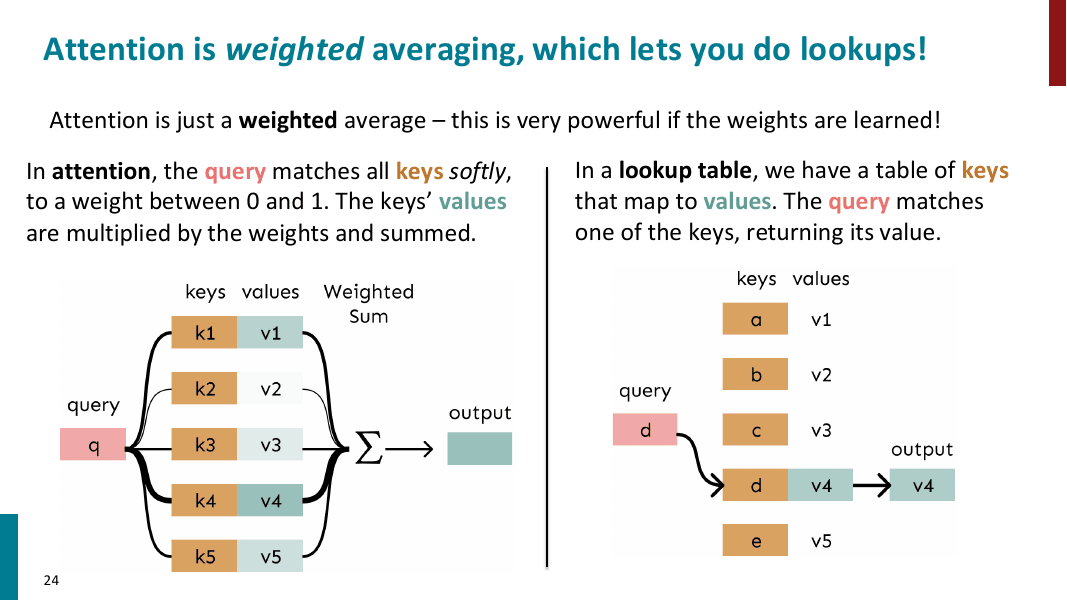

*Attention as a soft lookup: the query is compared with all keys, and the values are averaged with the resulting weights. — slide 24 of Stanford CS224N Lecture 5 (transformers), Winter 2026.*

### 2.4 Masking for decoder transformer

**Looking only backwards.** In a language model, position $t$ must predict token $t+1$ using tokens $1, \dots, t$
only. So the scores $e_{ij}$ with $j \gt i$ are set to $-\infty$ before the softmax: their weights become exactly $0$.
This **causal mask** is what makes the model *autoregressive*, and it is also what makes training efficient: one pass
over a text of $T$ tokens yields the model's prediction at *every* position, each position seeing only its past.

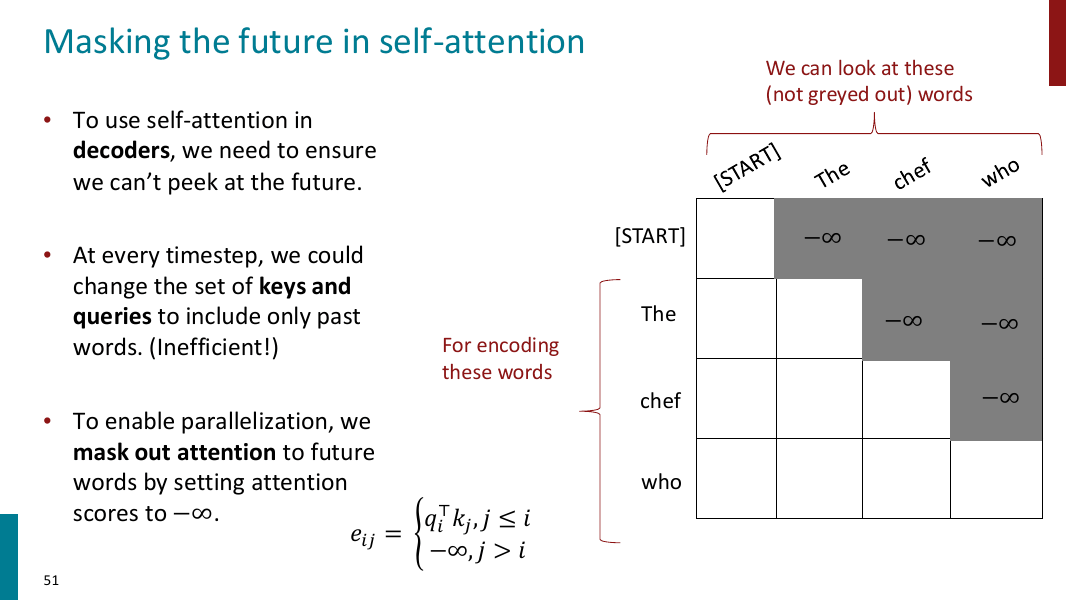

*Masking the future: scores of later positions are set to −∞, so their softmax weight is 0. — slide 50 of Stanford CS224N Lecture 5 (transformers), Winter 2026.*

**Demo: what two real heads do.** GPT-2 small has $12 \times 12 = 144$ heads. Each is a $T\times T$ attention
pattern on a given sentence. In the sentence below, head 11 of block 4 always looks at the previous token (a stripe
just below the diagonal); head 3 of block 4 makes "it" look at "cat". These patterns were not programmed; they
emerged from training.

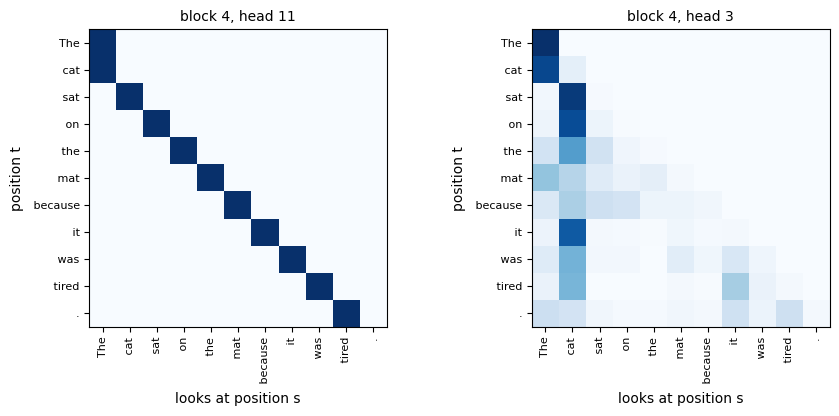

In [ ]:
sentence = "The cat sat on the mat because it was tired."
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
attention_heatmap(sentence, layer=4, head=11, ax=axes[0])
attention_heatmap(sentence, layer=4, head=3, ax=axes[1])
plt.tight_layout(); plt.show()

## 3. What is a token? &nbsp;&nbsp; <small>(20–30 min)</small>

### 3.1 An overlook of LLM

Terminology: a token is the language unit that a LLM predicts once at a time.

An overlook of LLM:

A sequence of tokens $(w_1,\dots,w_{t-1})$ -> a sequence of vectors $v_1,\dots,v_{t-1}$ -> (Attention, MLP, etc.) -> a probability distribution for $v_t$.


### 3.2 Why not predicting next word or next letter?

#### 3.2.1 Why not just use English words?
A natural idea: let $\mathcal{V}$ be the words of a dictionary. It fails for three reasons.`
1. **There is no finite list.** Vocabularies of real text keep growing with the corpus (new words, names, typos,
   inflections, compounds: *Transformerify*). Whatever is not in the list becomes a single "unknown" token, and the
   model can neither read nor write it.
2. **Words are not the right unit everywhere.** Code, numbers, URLs, LaTeX and Chinese (no spaces) have no words in the
   English sense. A model today must read all of them.
3. **Related forms would be unrelated symbols.** *learn, learned, learning, learner* would be four independent entries,
   each needing its own data to be learned.
4. **Too many words!** $|\mathcal{V}|$ would be too large.
5. **Long tail of infrequent words**.

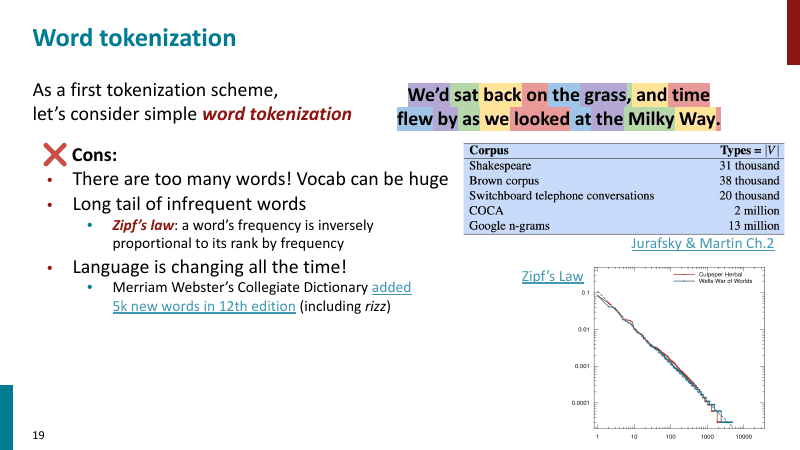

*Word tokenization, first problem: there are too many words, and most of them are rare (Zipf's law). — slide 19 of Stanford CS224N Lecture 14 (tokenization, guest lecture by Julie Kallini), Winter 2026.*

#### 3.2.2 Why not characters or bytes?

The opposite extreme: $\mathcal{V}$ = the 256 byte values. Nothing is ever unknown (no OOV). But

- a sentence becomes about
five times longer than in words, the cost of attention grows with $T^2$,
- and the model has to learn spelling,
word identity and grammar all from single letters before it can learn anything else.

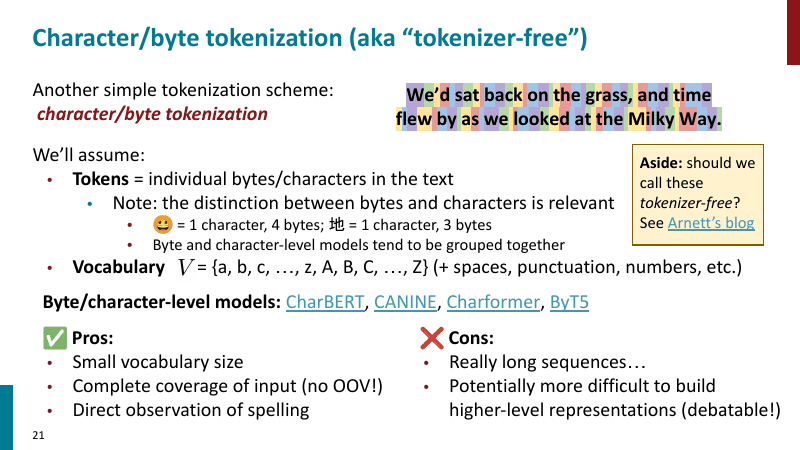

*Character or byte tokenization: a tiny vocabulary and nothing is unknown, but sequences become very long. — slide 21 of Stanford CS224N Lecture 14 (tokenization, guest lecture by Julie Kallini), Winter 2026.*

### 3.3 Subword tokens: the common practice

Meet in the middle: frequent words stay whole; rare words are cut into frequent pieces; in the worst case a piece is a single byte.

**Idea: Learn from the dataset of texts** what language units should be, instead of assuming it subjectively.

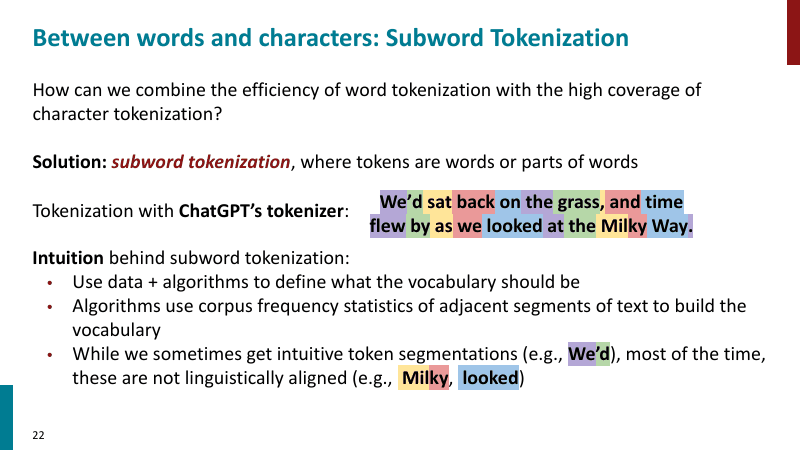

*Subword tokenization: frequent words stay whole, rare ones are split; pieces need not match linguistics. — slide 22 of Stanford CS224N Lecture 14 (tokenization, guest lecture by Julie Kallini), Winter 2026.*

### 3.4 Training the tokenizer (popular method: BPE)

Lets make a definition first.

#### 3.4.1 Definition of a tokenizer

A tokenizer is a triple $(\mathcal{V}, E,D)$, where
- $\mathcal{V}$ is an ordered list of tokens;
- $E$ is a deterministic program called encoder, which takes a sequence of words and outputs a sequence of tokens.
- $D$ is a deterministic program called decoder, which takes a sequence of tokens and outputs a sequence of words.

Before training LLM, we need to **train a tokenizer**, which means:
1. fix a dataset $D$ consisting of texts (e.g. TinyStories, WebText)
2. obtain a tokenizer using $D$.

**Remark: The tokenizer is fixed after training, and is independent of LLM training.**

#### 3.4.2 BPE: one of the most popular training methods of tokenizer

**3.4.2.1** Why BPE?

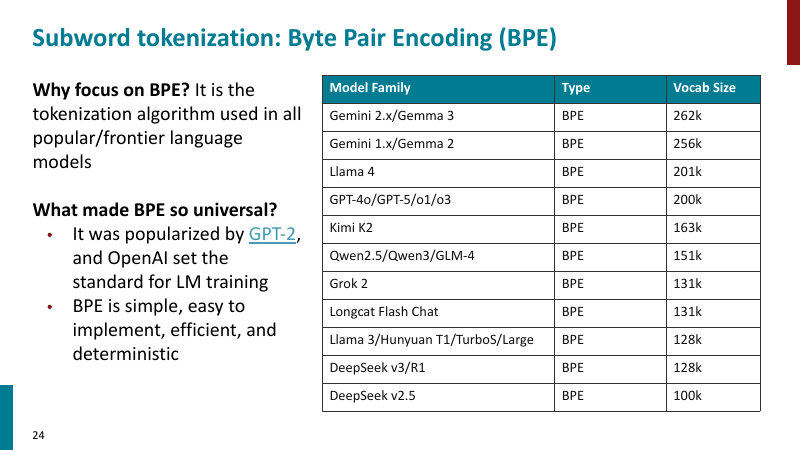

*BPE is what every current model family uses; vocabulary sizes range from 100k to 260k. — slide 24 of Stanford CS224N Lecture 14 (tokenization, guest lecture by Julie Kallini), Winter 2026.*

**3.4.2.2 The BPE algorithm**

The vocabulary (typically 50,000 to 200,000 pieces) is **learned from a corpus** by **byte-pair encoding (BPE)**, an algorithm from 1994 data compression:

1. Start with the 256 bytes as the vocabulary. Cut the corpus into words (so that merges never cross a space).
2. Count every pair of adjacent tokens in the corpus. Merge the most frequent pair into a new token; add it to the vocabulary.
3. Repeat step 2 until the vocabulary has the desired size. The ordered list of merges *is* the tokenizer.

To tokenize new text, apply the merges in the order they were learned. "Training the tokenizer" is this counting
procedure, run once on a large text before the model exists.

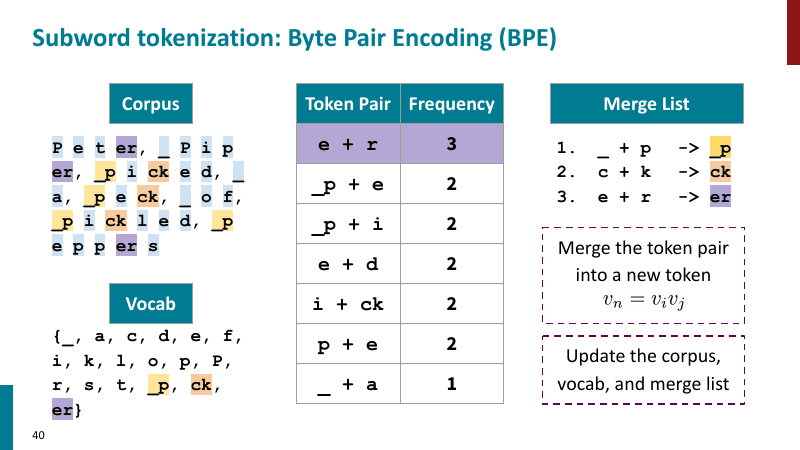

*One step of BPE training: count adjacent pairs, merge the most frequent one, update the corpus and the vocabulary. — slide 40 of Stanford CS224N Lecture 14 (tokenization, guest lecture by Julie Kallini), Winter 2026.*

This algorithm constructs the vocabulary set $\mathcal{V}$ from the dataset $D$.

Then the encoding and decoding programs are deterministic programs, obtained from $\mathcal{V}$.

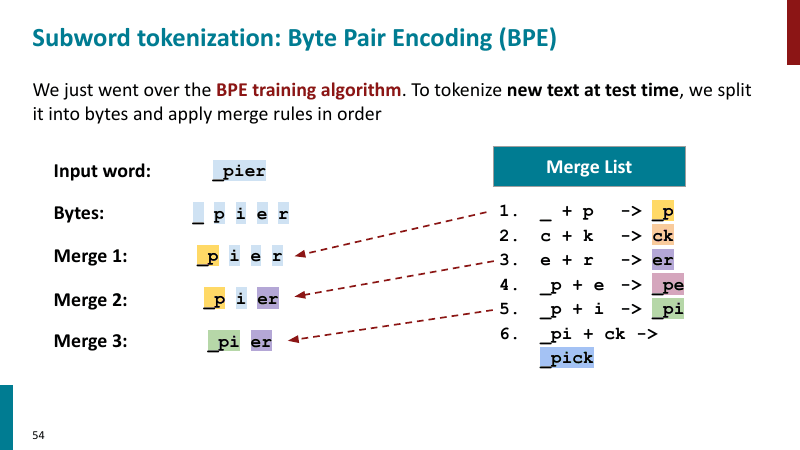

*Tokenizing new text: start from bytes and apply the learned merges in order. — slide 54 of Stanford CS224N Lecture 14 (tokenization, guest lecture by Julie Kallini), Winter 2026.*

### 3.4.3 Demo: test the tokenizer.
** Each colour is one token. Try your own sentences: English, a formula, numbers, code, another language.

In [ ]:
show_tokens("Vlad was mentioned in the last lecture, and misspelled as Vlaad")

print('\n')
show_tokens("Let G be a finite group and H a subgroup of G. Then |H| divides |G|.")
show_tokens("Riemann hypothesis: all nontrivial zeros of zeta(s) have real part 1/2")
show_tokens("1234567 + 7654321 = 8888888")
show_tokens("def f(x):\n    return x**2")
show_tokens("数学是科学的女王")
show_tokens("theorem theorem Theorem THEOREM")

In [ ]:
show_tokens("Shurui is laughing")

Things to notice: common English words are one token each, and the space *before* a word is part of the token
(`" theorem"` and `"theorem"` are different tokens; `"THEOREM"` is three). A rare word such as *Riemann* is cut into
pieces. Digits are grouped in an irregular way (`123|45|67`), which is one reason arithmetic is hard for these models.
Each Chinese character costs one to three tokens, each of them a single byte.


**Demo: train a tokenizer on twelve words.** The corpus is the toy example of the CS336 handout (Sennrich et al., 2016).
Watch which pairs get merged first and what the resulting pieces look like.

In [ ]:
corpus = "low low low low low lower lower widest widest widest newest newest newest newest newest newest"
final_words = train_bpe_demo(corpus, num_merges=8)
print("\nthe words, as sequences of tokens after 8 merges:")
for w in final_words: print("  ", " + ".join(w))

merge  1: 'e' + 's' -> 'es'   (the pair occurred 9 times)
merge  2: 'es' + 't' -> 'est'   (the pair occurred 9 times)
merge  3: 'est' + '_' -> 'est_'   (the pair occurred 9 times)
merge  4: 'l' + 'o' -> 'lo'   (the pair occurred 7 times)
merge  5: 'lo' + 'w' -> 'low'   (the pair occurred 7 times)
merge  6: 'n' + 'e' -> 'ne'   (the pair occurred 6 times)
merge  7: 'ne' + 'w' -> 'new'   (the pair occurred 6 times)
merge  8: 'new' + 'est_' -> 'newest_'   (the pair occurred 6 times)

the words, as sequences of tokens after 8 merges:
   low + _
   low + e + r + _
   w + i + d + est_
   newest_


**Demo: three tokenizers on the same texts.** GPT-2's vocabulary (2019) was learned from English web text. GPT-4o's
(2024, 200k tokens) and Qwen3's (2025, 152k tokens) were learned from multilingual text and code. The number of tokens
a text costs is the number of "slots" of the model it occupies, and it is what you pay for in an API.

In [ ]:
import tiktoken
gpt4o = tiktoken.get_encoding("o200k_base")                        # the tokenizer of GPT-4o / GPT-5 (downloaded once)
try:
    qwen3 = AutoTokenizer.from_pretrained("Qwen/Qwen3-0.6B")        # the tokenizer of the Qwen3 family
except Exception as e:
    qwen3 = None; print("Qwen3 tokenizer not available offline:", type(e).__name__)
texts = {"English": "The quick brown fox jumps over the lazy dog because it is late.",
         "LaTeX": r"\int_0^\infty e^{-x^2}\,dx = \frac{\sqrt{\pi}}{2}",
         "Chinese": "敏捷的棕色狐狸跳过了懒狗，因为天色已晚。",
         "numbers": "1234567 + 7654321 = 8888888",
         "Python": "def f(x):\n    return x**2"}
print(f"{'':10s}{'bytes':>7s}{'GPT-2':>8s}{'GPT-4o':>8s}{'Qwen3':>8s}")
for name, s in texts.items():
    print(f"{name:10s}{len(s.encode()):7d}{len(ids_of(s)):8d}{len(gpt4o.encode(s)):8d}{len(qwen3.encode(s)) if qwen3 else 0:8d}")
print()
show_tokens(texts["Chinese"], label="GPT-2"); show_tokens(texts["Chinese"], gpt4o, label="GPT-4o")
show_tokens(texts["numbers"], gpt4o, label="GPT-4o")
if qwen3: show_tokens(texts["numbers"], qwen3, label="Qwen3")

            bytes   GPT-2  GPT-4o   Qwen3
English        63      14      14      14
LaTeX          49      29      26      26
Chinese        60      45      19      15
numbers        27      13      13      25
Python         25      13       9       9



Chinese costs GPT-2 three times as many tokens as GPT-4o: the 2019 vocabulary had almost no Chinese merges, so every
character falls back to bytes. Digits are also a design decision: GPT-4o groups them in threes, Qwen3 deliberately
keeps **one digit per token** so that arithmetic is easier to learn.

**Consequences you will meet.** A model cannot count the letters of "strawberry": it sees three opaque pieces, not
nine letters (CS224N slide below). Numbers are chunked, so place value is not visible. Tokens that were frequent in the
tokenizer's corpus but rare in the model's training data ("glitch tokens") have essentially untrained vectors and cause
erratic behaviour. And a language that tokenizes badly gets fewer "slots" of context and costs more.

### 3.5 Challenges of Subwords Tokenizers

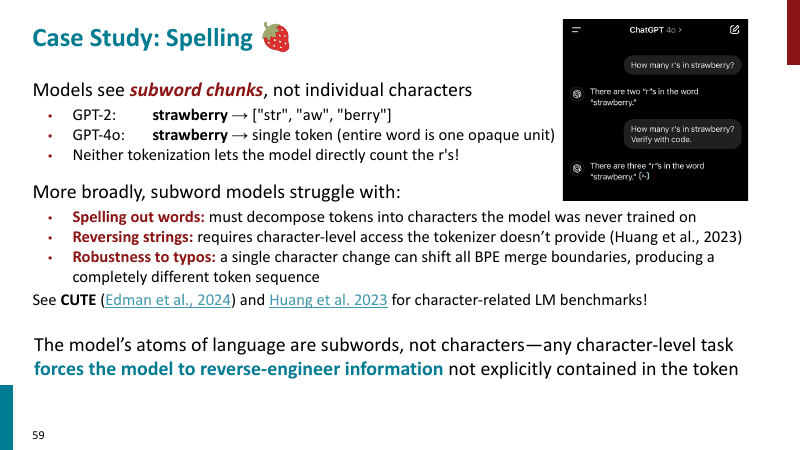

*A model sees pieces, not letters: spelling questions, reversing strings and typos are hard for a reason. — slide 59 of Stanford CS224N Lecture 14 (tokenization, guest lecture by Julie Kallini), Winter 2026.*

### 3.6 Summary

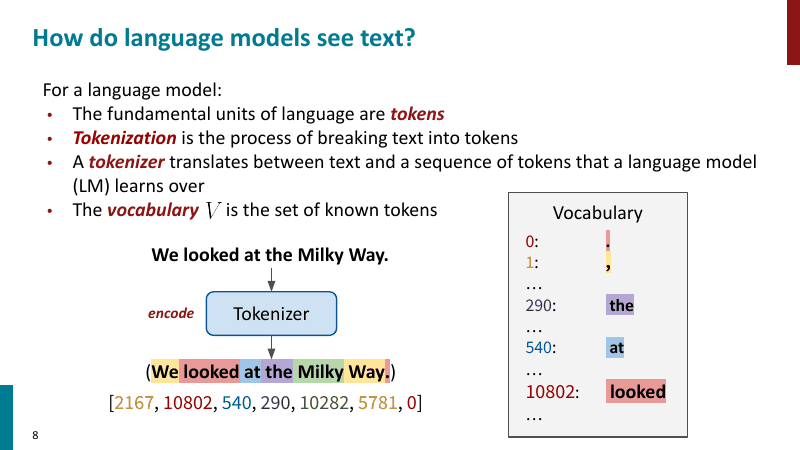

*How a language model sees text: the tokenizer cuts the text into pieces from a fixed vocabulary and replaces each piece by its index. — slide 8 of Stanford CS224N Lecture 14 (tokenization, guest lecture by Julie Kallini), Winter 2026.*

### 3.7 For Other applications

To train transformer models for other purposes, one has to define what a token is in that setting.

**Example:**

1. DNA prediction
2. Time series prediction
3. Knot theory? Protein?

**Remark:** special tokens `<EOS>`, etc.

## 4. Embeddings: represent tokens in terms of vectors &nbsp;&nbsp; <small>(30–50 min)</small>

### 4.1 Personal understanding of LLM

Personally, I think **the key idea in NN/DL/Transformer model** is:

1. Learning only happens in the linear parts of the model, which are controlled by a finite set of parameters (weights).
2. Non-linearity part is fixed, i.e. the activation functions are pre-fixed before training LLM; tokenizer is fixed before training LLM;
3. By universal approximation theorem and real life observations, this is enough to express unctions/tasks in daily life.

The **working "assumptions"** are:
1. **Machine can magically learn**: The design of the architecture (how one stacks linear/nonlienear blocks) reflects heuristics of human understanding or function approximations, and then enough data + reasonable training loss (proxy for success of tasks)+ reasonable optimizer, will make the model realize these huristics via "deep learning".
2. **Representation theory:** Tasks and information are represented by linear algebra data (vectors, matrices, etc.)


**Recall:**

One way of understanding attention is to assume the way how tokens in the context window are interacted can be represented by $Q,K,V$ matrices, and the machine will learn what $Q,K,V$ are to realize the attention heuristics (query, key, value).


**Now:**

Therefore, we need to let the model **learn how to represent tokens in terms of vectors**. This is the embedding layer.


### 4.2 Embedding layer

### 4.2.1 Representation

The **embedding matrix** $E \in \mathbb{R}^{V\times d}$
gives one vector $\in \mathbb{R}^d$ per token: token number $i$ becomes row $E_i \in \mathbb{R}^d$. That is the whole first layer of the
model: a lookup in a table.

Equivalently, $E^{\top}$ is a linear map $\mathbb{R}^V \to \mathbb{R}^d$ applied to the one-hot vector $e_i$.




This is one of the linear part of the model. $E$ is part of $\theta$: it starts random and is adjusted during learning/training, to make "next token prediction" task better (minimizing the loss function).

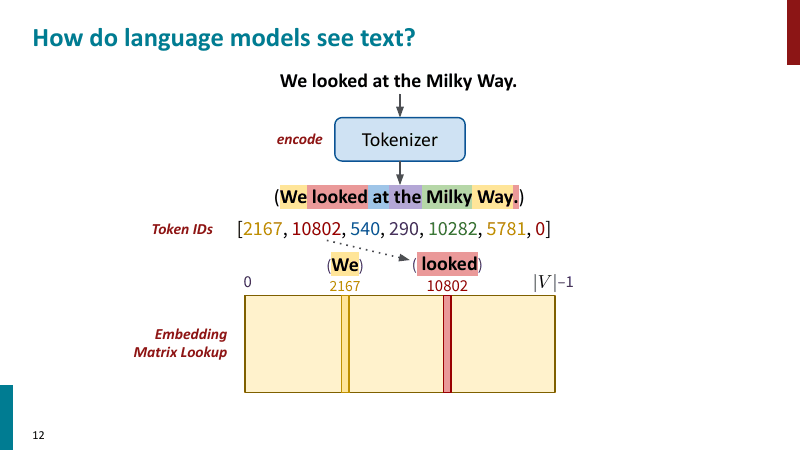

*From token ids to vectors: each id selects one row of the embedding matrix. — slide 12 of Stanford CS224N Lecture 14 (tokenization, guest lecture by Julie Kallini), Winter 2026.*

### 4.2.2 Heuristics

1. **cosine-similarity should reflect tokens' correlation**. The cosine-similarity is defined by $\cos(u, v) = \langle u, v \rangle / (\lVert u \rVert\, \lVert v \rVert)$.
2. tokens used in similar contexts end up with similar vectors (the "distributional hypothesis": *you shall know a word by the company it keeps*). I would call this **"Yoneda's lemma in NLP"**.


## 4.3 Demo with GPT-2 trained weights
In GPT-2 small, $E$ is $50{,}257 \times 768$: 38.6 million numbers, 31% of the model.

E has shape (50257, 768)
the vector of ' theorem' starts with [-0.119, -0.099, -0.059, -0.298, 0.072, -0.005, -0.372, 0.124] ... (768 numbers in total)


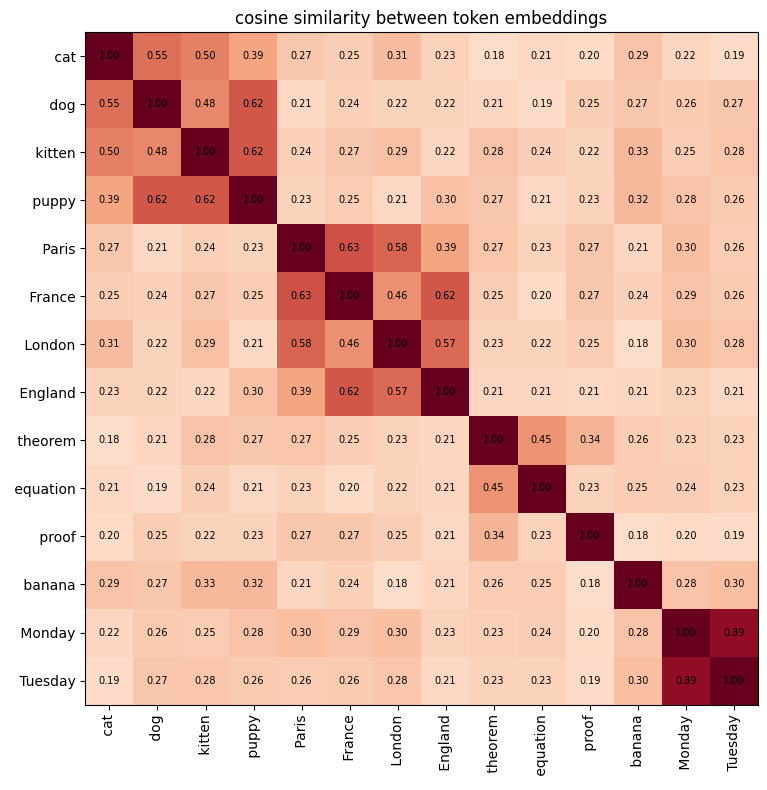

In [ ]:
print("E has shape", tuple(E.shape))
print("the vector of ' theorem' starts with", [round(x, 3) for x in vec(" theorem")[:8].tolist()], "... (768 numbers in total)")
similarity_heatmap([" cat", " dog", " kitten", " puppy", " Paris", " France", " London", " England", " theorem", " equation", " proof", " banana", " Monday", " Tuesday"])

#### Play around!

In [ ]:
def word_similarity(word1, word2):
    """cosine similarity of the embedding vectors of two words.
    A leading space is added (that is how a word appears inside a sentence); a word that the tokenizer
    cuts into several tokens gets the average of its token vectors."""
    vecs, pieces = [], []
    for w in (word1, word2):
        ids = ids_of(" " + w.strip())
        pieces.append([tokenizer.decode([i]) for i in ids])
        vecs.append(E[ids].mean(dim=0))
    sim = F.cosine_similarity(vecs[0], vecs[1], dim=0).item()
    print(f"{word1!r} → tokens {pieces[0]}    {word2!r} → tokens {pieces[1]}    cosine similarity = {sim:.3f}")
    return sim

word_similarity("cat", "dog")
word_similarity("theorem", "banana")
word_similarity("Riemann", "Euler")      # both names are cut into pieces; the pieces' vectors are averaged

'cat' → tokens [' cat']    'dog' → tokens [' dog']    cosine similarity = 0.550
'theorem' → tokens [' theorem']    'banana' → tokens [' banana']    cosine similarity = 0.257
'Riemann' → tokens [' R', 'iem', 'ann']    'Euler' → tokens [' E', 'uler']    cosine similarity = 0.467


0.4667432904243469

In [ ]:
# interactive version: type two words in the boxes and press Enter
try:
    from ipywidgets import interact, Text
    interact(word_similarity, word1=Text(value="king", continuous_update=False), word2=Text(value="queen", continuous_update=False));
except ImportError:
    print("ipywidgets is not installed here; call word_similarity('king', 'queen') instead")

interactive(children=(Text(value='king', continuous_update=False, description='word1'), Text(value='queen', co…

### 4.4 Positions &nbsp; <small>(briefly)</small>

#### 4.4.1 position information should be added

Attention does not know the order of the tokens: permute the input vectors and the outputs are permuted the same way. So position must be put *into* the vectors.

GPT-2 does the simplest thing: a second table $P \in \mathbb{R}^{1024 \times d}$, one learned vector per position, added to the token vector, $x_t = E_{x_t} + P_t$. The number $1024$ is the maximum context: there is no row $P_{1025}$.

**Remark**: again this idea aligns with the philosophy I proposed: if you do not know how to deal with something, simply try to express it in linear terms and let the model figure it out during its training time.

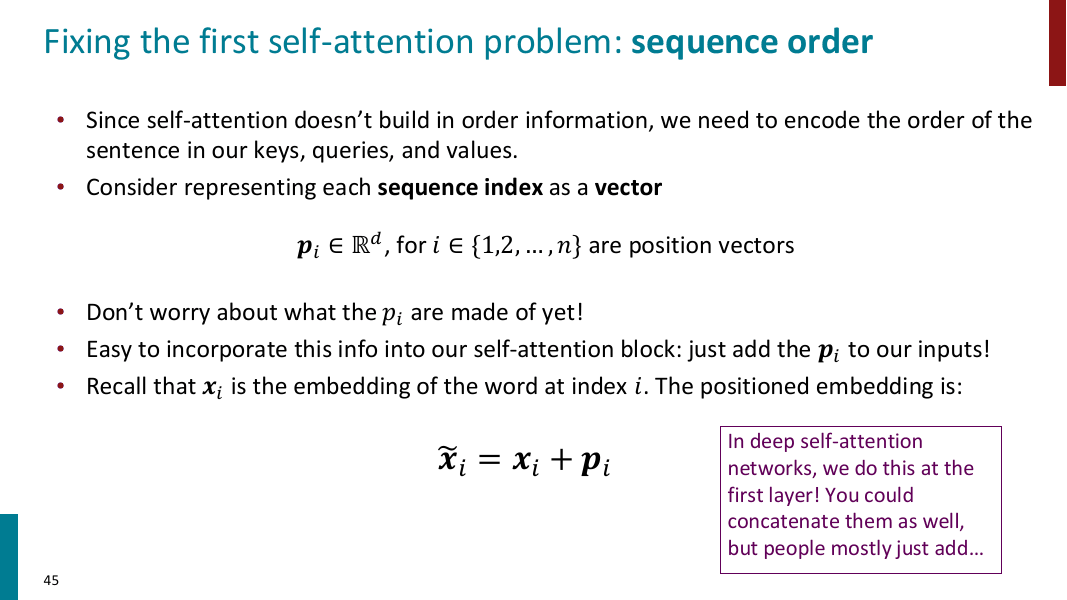

*Position vectors: a vector per position, added to the token vector so that the same word at different places gets different inputs. — slide 44 of Stanford CS224N Lecture 5 (transformers), Winter 2026.*

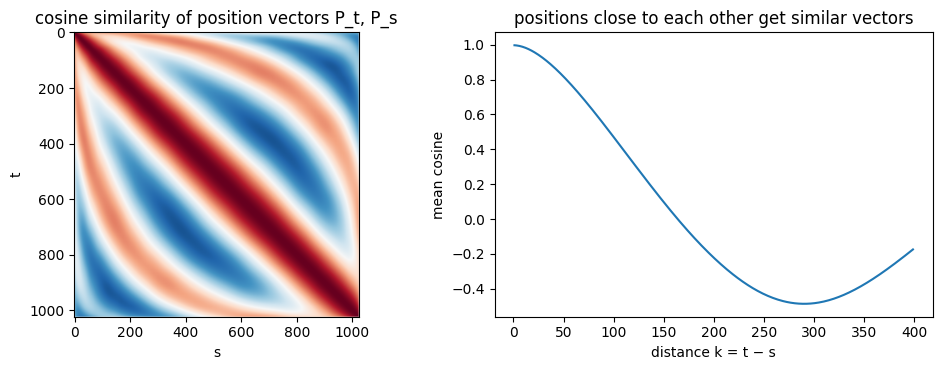

In [ ]:
position_similarity_plot()

### 4.4.2 ROPE (the common practice these days)

**RoPE is the standard today.** Models since Llama (2023) use *rotary position embeddings*:

nothing is added to $x_t$; instead, inside every attention head, the query and key vectors are rotated by an angle proportional to the
position.

Split $q \in \mathbb{R}^{d_k}$ into $d_k/2$ planes and rotate the $j$-th plane at position $t$ by $t\,\theta_j$,
with $\theta_j = \Theta^{-2j/d_k}$ (geometric frequencies). Because rotations compose,

$$ \langle R_t\, q,\; R_s\, k \rangle = \langle R_{t-s}\, q,\; k \rangle : $$

the attention score depends only on the **relative** position $t - s$. There is no table, no maximum length, and no
parameter. We will not go further into it; just recognize the name when you read a model card.

## 4.5 Another viewpoint of embedding layer and transformer: a vector in context

After the embedding, the vector at position $t$ depends only on token $x_t$.

Each block of the model then *rewrites* it

1. using the other positions (attention)
2. a position-wise computation (the MLP: linear+activation maps).

**Idea:** (forgive me for abusing the math term)
1. Linear repsentation theory: the model will learn the best way to represent these infomation into linear algebra structures and learn the best way to rewrite them, so that the model can output the "best" probability prediction minimizing the loss.
2. Yoneda's lemma: The same token `" bank"` in two sentences starts with identical vectors and drifts apart block by block during learning. This is the sense in which a transformer computes **contextual** representations.

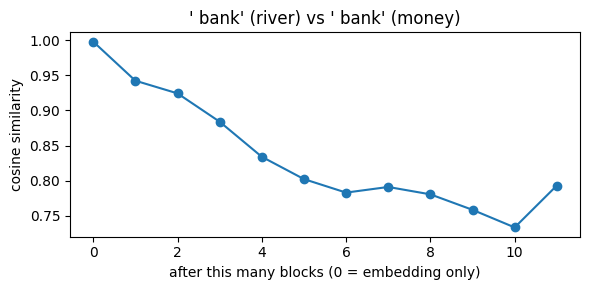

In [ ]:
river = vectors_through_the_blocks("He sat on the river bank and watched the water flow.", " bank")
money = vectors_through_the_blocks("She deposited the money in the bank account.", " bank")
plt.figure(figsize=(6, 3)); plt.plot([cosine(u, v) for u, v in zip(river, money)], "o-")
plt.xlabel("after this many blocks (0 = embedding only)"); plt.ylabel("cosine similarity")
plt.title("' bank' (river) vs ' bank' (money)"); plt.tight_layout(); plt.show()

## 5. The output layer &nbsp;&nbsp; <small>(50–60 min)</small>

### 5.1. Definition

After the $L$ blocks, the last position holds a vector $h_T \in \mathbb{R}^d$ that has gathered, through attention,
whatever the model found relevant in the whole context. The prediction is read off by one matrix and a softmax:

$$ o = U\, h_T \in \mathbb{R}^{V} \quad (U \text{ is } V\times d), \qquad\qquad p_\theta(x_{T+1} = v \mid x_{1:T}) = \frac{e^{o_v}}{\sum_{w\in\mathcal{V}} e^{o_w}} . $$

* The $V$ numbers $o_v$ are the **logits** (log-probabilities up to a common constant). The softmax turns any vector
  into a probability distribution; it is invariant under adding a constant to all coordinates.
* The matrix $U$ is called the **unembedding**. In GPT-2 it is the embedding matrix again, $U = E$: logit $v$ is the
  inner product $\langle E_v, h_T \rangle$, so *the model predicts the tokens whose embedding points in the direction
  of $h_T$*. Larger models usually give $U$ its own parameters.
* This is a $V\times d$ matrix times a vector: $50{,}257 \times 768 \approx 39$ million multiplications per
  predicted token, as much as five of the twelve blocks for a model this small.

### 5.2. Demo

**Demo: compute the prediction by hand.** Three lines: take $h_T$ from the model, multiply by $E$, apply the softmax.

logits: 50,257 numbers, from -111.3 to -81.6;  probabilities sum to 1.0000
identical to the model's own output: True


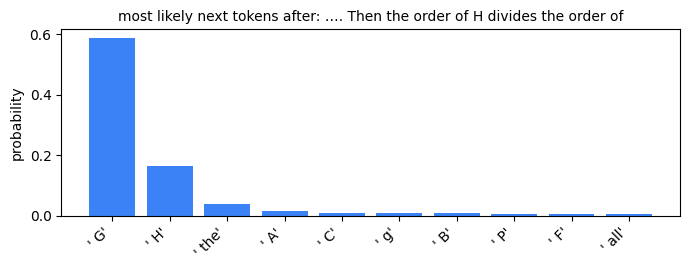

In [ ]:
prompt = "Let G be a finite group and H a subgroup of G. Then the order of H divides the order of"
h_T = last_vector(ids_of(prompt))              # the final vector at the last position: 768 numbers
logits = E @ h_T                               # (V x d) times (d): one score per token of the vocabulary
probs = torch.softmax(logits, dim=0)           # scores -> probabilities, summing to 1
print(f"logits: {len(logits):,} numbers, from {logits.min():.1f} to {logits.max():.1f};  probabilities sum to {probs.sum():.4f}")
print("identical to the model's own output:", torch.allclose(probs, next_token_probs(ids_of(prompt)), atol=1e-4))
plot_top_tokens(probs, title=f"most likely next tokens after: …{prompt[-42:]}")

### 5.3 Generating next token

**Softmax, then sample.** The model's answer is not a token but a distribution. Producing a token means *drawing*
from it (sampling), or taking the most likely one (greedy). This choice is made outside the model, by the program
calling it.

## 6. Inference: frozen weights, autoregression, temperature &nbsp;&nbsp; <small>(60–80 min)</small>

### 6.1 Model weights are fixed during inference time
**The weights are frozen.** When you use a model, $\theta$ does not change. A forward pass is the evaluation of a
fixed function: matrices multiplying vectors, a few softmaxes. Nothing is learned from your conversation; the only
state is the *context*, the tokens in the window.

In codes: (`model.eval()`, `torch.no_grad()`).

### 6.2 Autoregression
**Autoregression.** To generate text: run $f_\theta$ on the prompt, draw $x_{T+1}$ from the output distribution,
append it to the context, run again, and so on, one token per forward pass. Each new token's vector, through
attention, has access to all previous ones. This is the loop behind every chatbot; the only efficiency trick is a
cache that keeps the keys and values of earlier positions so they are not recomputed (the *KV cache*).

### 6.3 Demo: different temparatures
**Demo: generate, one token at a time, at different temperatures.** The **temperature** $\tau > 0$ rescales the
logits before the softmax, $p_v \propto e^{o_v/\tau}$: a Boltzmann distribution. $\tau \to 0$ concentrates all mass
on the most likely token (greedy decoding); $\tau = 1$ is the model's own distribution; $\tau \to \infty$ tends to
uniform. The entropy of the distribution increases with $\tau$. Watch the greedy output fall into a loop, a classic
failure, and the high-temperature output dissolve into noise.

In [ ]:
prompt = "The proof of the theorem proceeds by induction on"
for tau in [0, 0.5, 0.8, 1.2, 2.0]:
    print(f"--- temperature {tau} ---"); generate(prompt, temperature=tau, max_new_tokens=35)

--- temperature 0 ---
The proof of the theorem proceeds by induction on the following theorem:

Proof of the theorem is

Proof of the theorem is

Proof of the theorem is

Proof of the theorem is

Proof
--- temperature 0.5 ---
The proof of the theorem proceeds by induction on the theory of the Trinity as follows:

Theorem 1. Theorem 2. Theorem 3. Theorem 4. Theorem 5. Theorem 6. The
--- temperature 0.8 ---
The proof of the theorem proceeds by induction on top of the theorem Proof as follows:

Proof of Proof $\alpha \rightarrow $\infty \alpha $\left\Foldin \beta \right
--- temperature 1.2 ---
The proof of the theorem proceeds by induction on sort_stream . Proof as basis of **conductors of propagation **cannabis satisfies account of OPR induction for the theorems of GREEN 1 (followed by
--- temperature 2.0 ---
The proof of the theorem proceeds by induction on sort lonestream prison Proof Mark 6 Hem agricultural Tel:" Gar throughout Blankfiction spreadsheet Son satisfies link Hang Oizard l

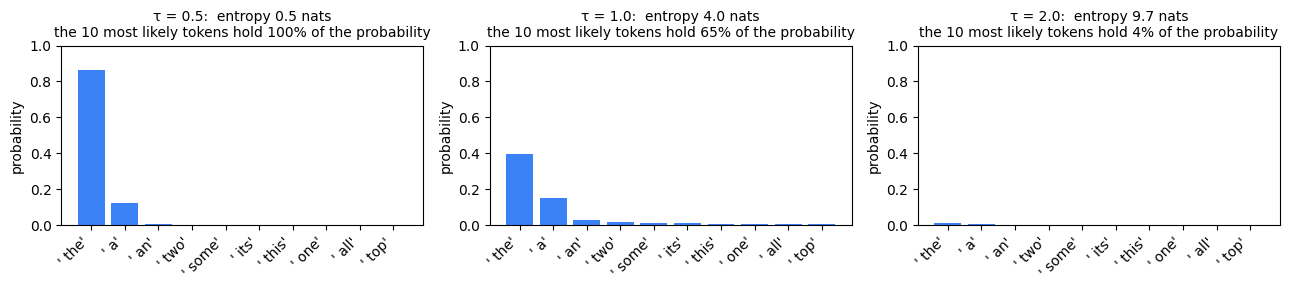

In [ ]:
# the same distribution at three temperatures
ids = ids_of(prompt)
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, tau in zip(axes, [0.5, 1.0, 2.0]):
    p = next_token_probs(ids, temperature=tau); H = -(p * torch.log(p + 1e-30)).sum()
    plot_top_tokens(p, title=f"τ = {tau}:  entropy {H:.1f} nats\nthe 10 most likely tokens hold {p.topk(10).values.sum():.0%} of the probability", ax=ax); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

### 6.4 Common practice of choosing temparatures

In practice one also truncates the distribution to the most likely tokens (**top-$p$** keeps the smallest set of tokens
whose total probability is at least $p$, then renormalizes); chat products run at $\tau$ around $0.6$–$1$ with
top-$p$ around $0.9$–$0.95$.

## Other topics: Masking and encoder–decoder Transfomer models

The 2017 transformer (built for translation) had two stacks: an **encoder** reading the source sentence with
attention in both directions (no mask), and a **decoder** generating the target, with the causal mask and an extra
attention into the encoder's outputs. Later work kept one or the other:

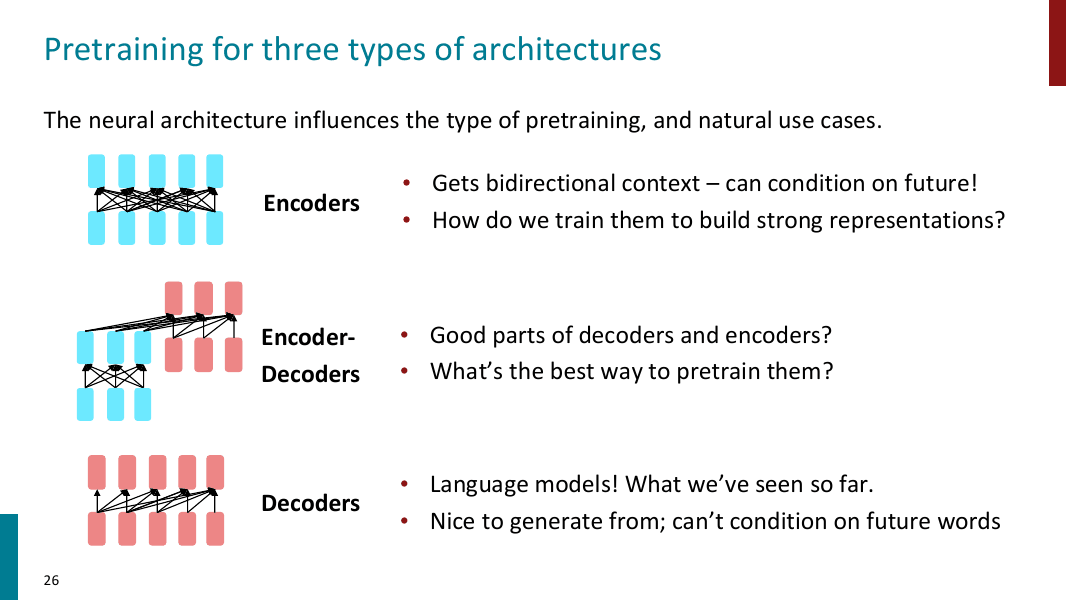

*Three ways to use the transformer: encoders (read, bidirectional), decoders (generate, causal), or both. — slide 24 of Stanford CS224N Lecture 7 (pretraining), Winter 2026.*

* **Encoder only** (BERT, 2018): every position sees the whole input. Good for classifying or labelling a given text;
  cannot generate.
* **Decoder only** (GPT, 2018–today): one stack, causal mask, trained to predict the next token. Every LLM you use is
  a decoder.
* **Encoder–decoder** (T5, translation systems): both.

### Where we are

| step | map | GPT-2 small |
|---|---|---|
| tokenize (§3) | text → $(x_1, \dots, x_T)$ | $V = 50{,}257$ pieces |
| embed (§4) | $x_t \mapsto E_{x_t} + P_t \in \mathbb{R}^d$ | $d = 768$ |
| $L$ blocks (last week + next lecure) | attention mixes positions; an MLP rewrites each position | $L = 12$, $h = 12$ heads |
| output layer (§5) | $h_T \mapsto \operatorname{softmax}(U h_T)$ | $U = E$ |
| sample (§6) | draw $x_{T+1}$, append, repeat | temperature, top-$p$ |

#### On Wednesday: More on training and $L$ blocks!